In [3]:
!pip install ucimlrepo

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from pathlib import Path

In [5]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = BASE_DIR / "dataset"
DATA_DIR.mkdir(exist_ok=True)

In [6]:
heart_disease = fetch_ucirepo(id=45)

In [8]:
df = pd.concat(
    [heart_disease.data.features,
     heart_disease.data.targets],
    axis=1
)

print("Dataset downloaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [9]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Column names
print("Columns:", df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object


In [10]:
missing_values = df.isnull().sum()

In [11]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_report[missing_report["Missing Values"] > 0])

,Missing Values,Missing Percentage
ca,4,1.320132
thal,2,0.660066


In [12]:
# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [13]:
# Identify numerical columns
numerical_cols = df.select_dtypes(
    include=np.number
).columns

# Fill numerical missing values using median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Check missing values again
print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [14]:
# Convert multiclass target into binary classification
df["num"] = (df["num"] > 0).astype(int)

print(df["num"].value_counts())

num
0    164
1    139
Name: count, dtype: int64


In [15]:
# Independent variables
X = df.drop("num", axis=1)

# Dependent variable
y = df["num"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (303, 13)
Target Shape: (303,)


In [16]:
# Descriptive statistics
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


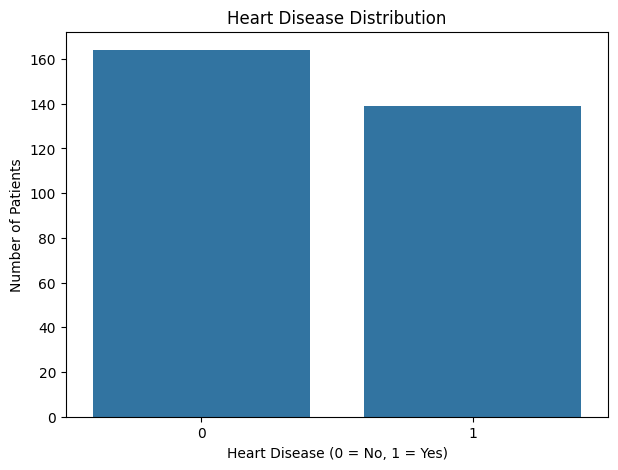

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="num")

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

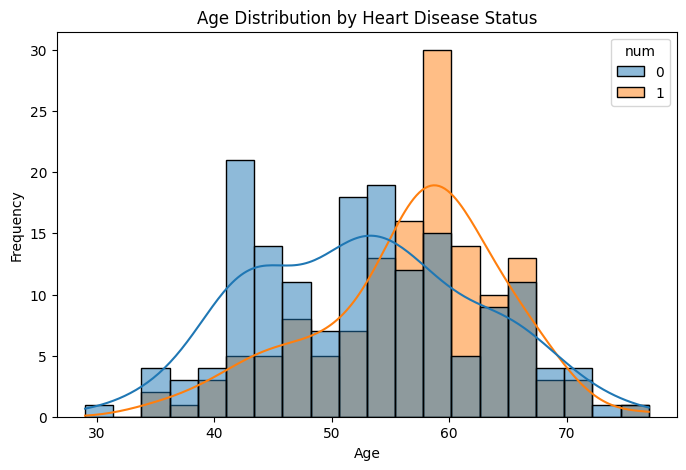

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="num",
    kde=True,
    bins=20
)

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

- Most patients in the dataset are between approximately 40 and 65 years old.
- Patients with heart disease show a noticeable concentration around 55–60 years.
- Patients without heart disease are also distributed across the 40–60 age range.
- Both distributions overlap considerably.

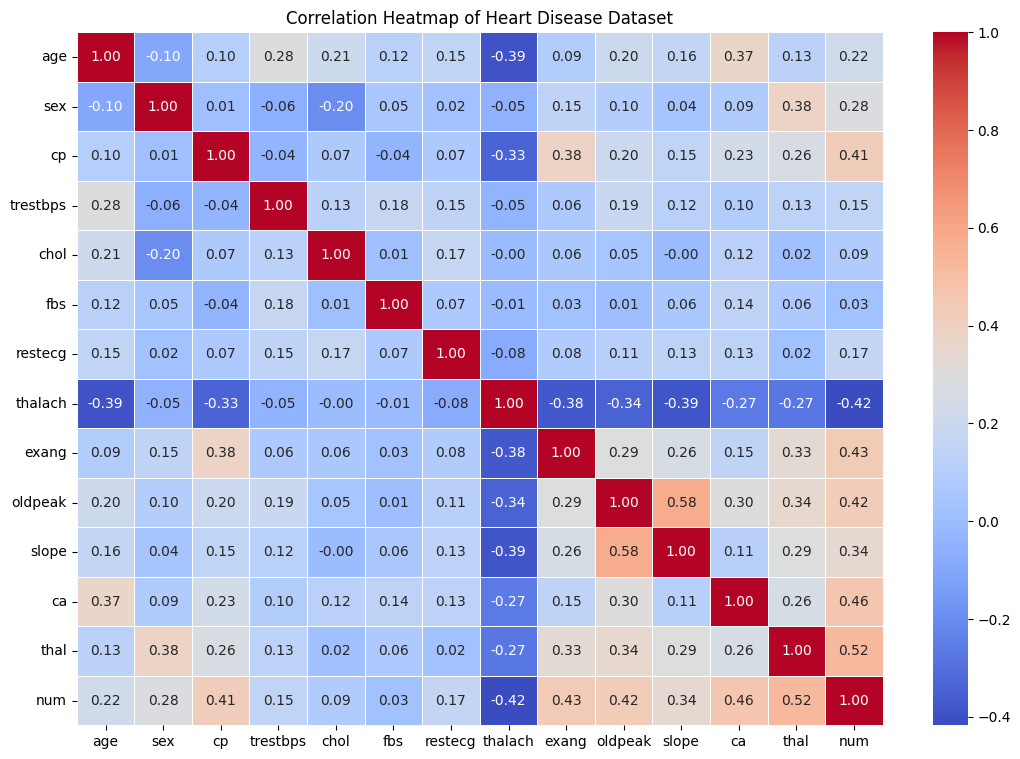

In [19]:
plt.figure(figsize=(13, 9))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Heart Disease Dataset")
plt.show()

**impotant observation**
thal: Shows the strongest positive correlation with the target.
ca: Shows a moderate positive correlation.
exang: Exercise-induced angina has a positive association with the target.
oldpeak: ST depression shows a positive association.
thalach: Shows a negative association with the target.

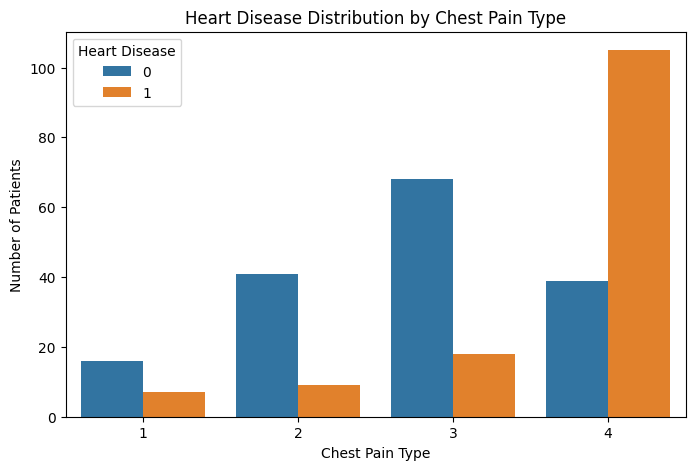

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="cp",
    hue="num"
)

plt.title("Heart Disease Distribution by Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.legend(title="Heart Disease")

plt.show()

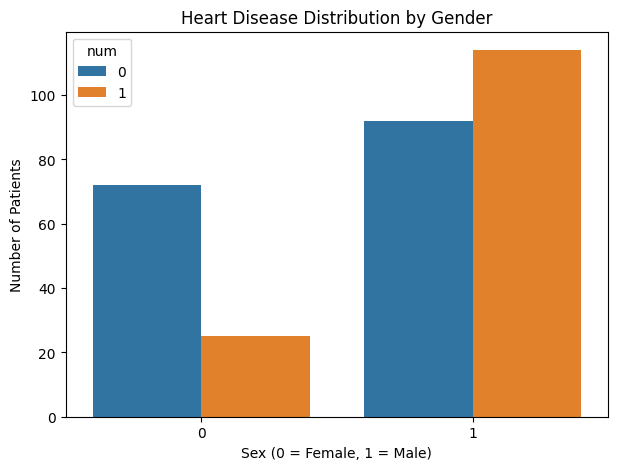

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sex",
    hue="num"
)

plt.title("Heart Disease Distribution by Gender")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Number of Patients")

plt.show()

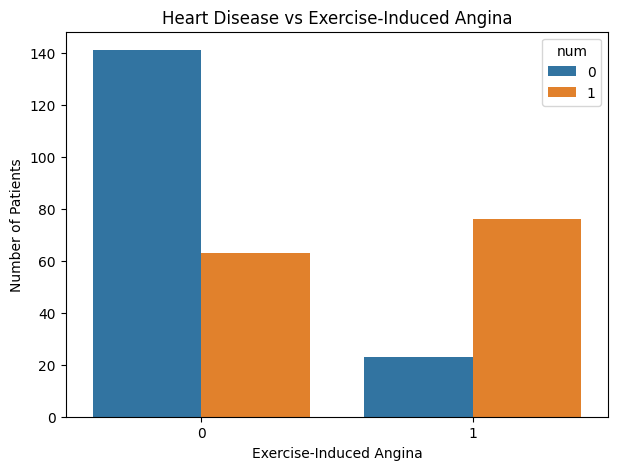

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="exang",
    hue="num"
)

plt.title("Heart Disease vs Exercise-Induced Angina")
plt.xlabel("Exercise-Induced Angina")
plt.ylabel("Number of Patients")

plt.show()

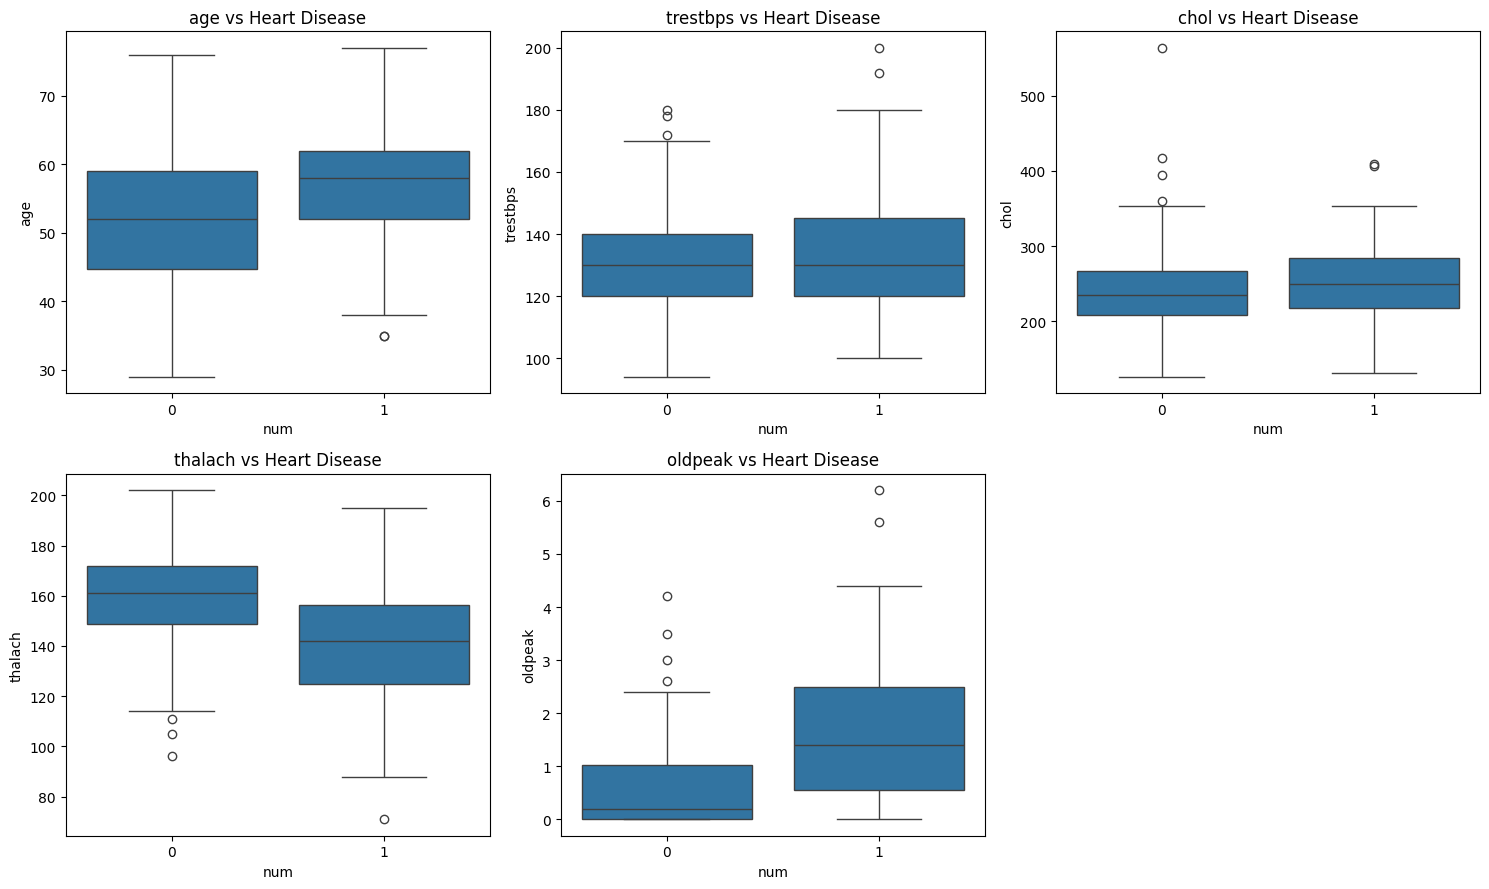

In [24]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(numerical_features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="num",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} vs Heart Disease")

# Hide unused subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [25]:
# Gender-wise heart disease percentage
gender_analysis = pd.crosstab(
    df["sex"],
    df["num"],
    normalize="index"
) * 100

gender_analysis.columns = [
    "No Heart Disease",
    "Heart Disease"
]

display(gender_analysis.round(2))

,No Heart Disease,Heart Disease
sex,,
0,74.23,25.77
1,44.66,55.34


In [26]:
cp_analysis = pd.crosstab(
    df["cp"],
    df["num"],
    normalize="index"
) * 100

cp_analysis.columns = [
    "No Heart Disease",
    "Heart Disease"
]

display(cp_analysis.round(2))

,No Heart Disease,Heart Disease
cp,,
1,69.57,30.43
2,82.00,18.00
3,79.07,20.93
4,27.08,72.92


- Chest pain type 4 has the highest heart disease-positive proportion (72.92%).
- Type 2 has the lowest positive proportion (18%).

- Type 1 and type 3 show intermediate proportions.


In [27]:
from sklearn.model_selection import train_test_split

# Reload original dataset
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features.copy()
y = heart_disease.data.targets["num"].copy()

# Convert target into binary classification
y = (y > 0).astype(int)

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (242, 13)
Testing Features: (61, 13)

Training Target Distribution:
num
0    131
1    111
Name: count, dtype: int64

Testing Target Distribution:
num
0    33
1    28
Name: count, dtype: int64


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical features
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Categorical features
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

print("Three machine learning algorithms defined.")

Three machine learning algorithms defined.


In [30]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-Fold Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

cv_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

# Display comparison
cv_df = pd.DataFrame(cv_results)

display(
    cv_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8471,0.8768,0.7834,0.8245,0.9025
1,Random Forest,0.8139,0.8129,0.7739,0.7900,0.8927
2,Support Vector Machine,0.8139,0.8303,0.7648,0.7893,0.8884


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

trained_models = {}
test_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Probability predictions
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Store trained model
    trained_models[name] = pipeline

    # Calculate evaluation metrics
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display final results
test_df = pd.DataFrame(test_results)

display(test_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
1,Random Forest,0.8525,0.8065,0.8929,0.8475,0.9432
2,Support Vector Machine,0.8852,0.8387,0.9286,0.8814,0.9643


In [32]:
for name, pipeline in trained_models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    y_pred = pipeline.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ]
    ))


Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.93      0.85      0.89        33
   Heart Disease       0.84      0.93      0.88        28

        accuracy                           0.89        61
       macro avg       0.89      0.89      0.89        61
    weighted avg       0.89      0.89      0.89        61


Random Forest
                  precision    recall  f1-score   support

No Heart Disease       0.90      0.82      0.86        33
   Heart Disease       0.81      0.89      0.85        28

        accuracy                           0.85        61
       macro avg       0.85      0.86      0.85        61
    weighted avg       0.86      0.85      0.85        61


Support Vector Machine
                  precision    recall  f1-score   support

No Heart Disease       0.93      0.85      0.89        33
   Heart Disease       0.84      0.93      0.88        28

        accuracy                           0.89        61
    

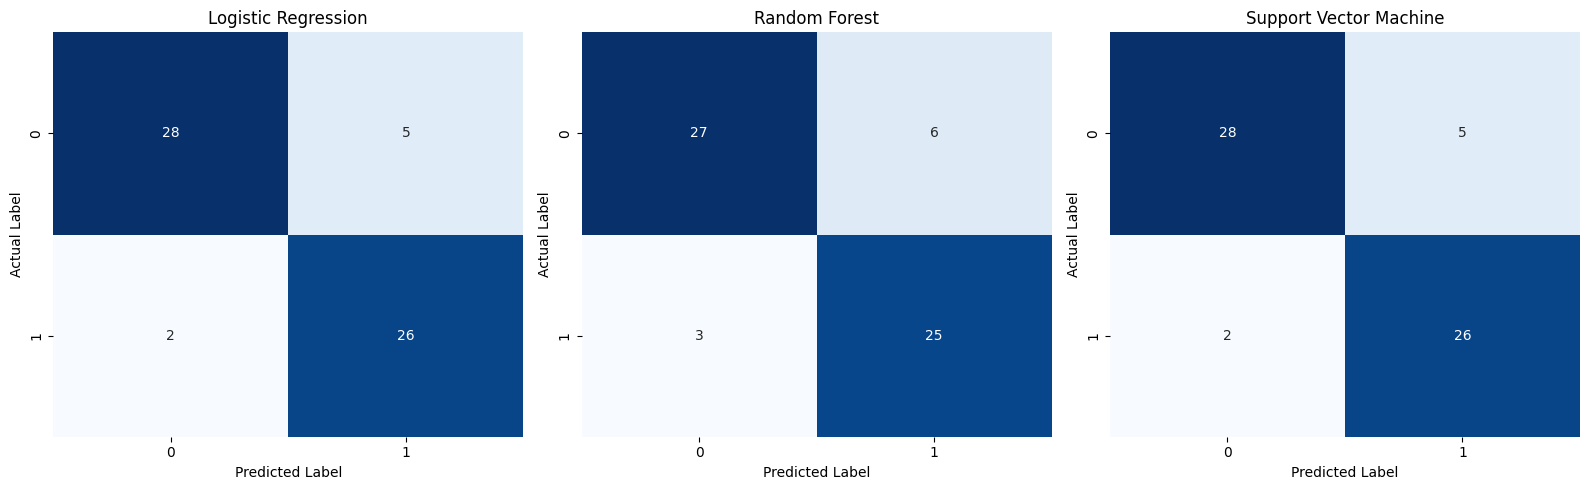

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pipeline) in zip(
    axes,
    trained_models.items()
):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        cbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

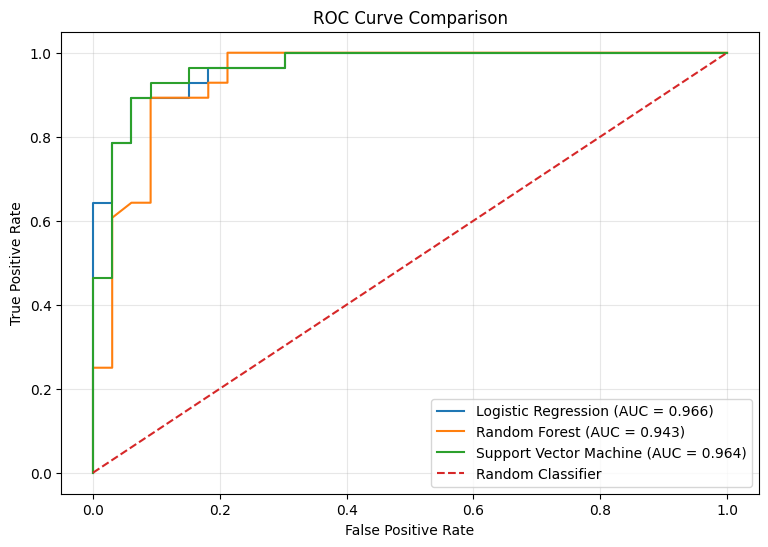

In [34]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 6))

for name, pipeline in trained_models.items():

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Unsupervised Learning- using Kmeans clustering**

In [35]:
# Transform original features without using target labels
X_cluster = preprocessor.fit_transform(X)

print("Clustering data shape:", X_cluster.shape)

Clustering data shape: (303, 28)


In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_scores = []

k_values = range(2, 8)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    inertia_values.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(X_cluster, cluster_labels)
    )

cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_scores
})

display(cluster_evaluation.round(4))

,K,Inertia,Silhouette Score
0,2,2250.8064,0.1652
1,3,2064.8470,0.1262
2,4,1949.1942,0.1201
3,5,1864.5617,0.1074
4,6,1801.8197,0.0931
5,7,1740.5364,0.0835


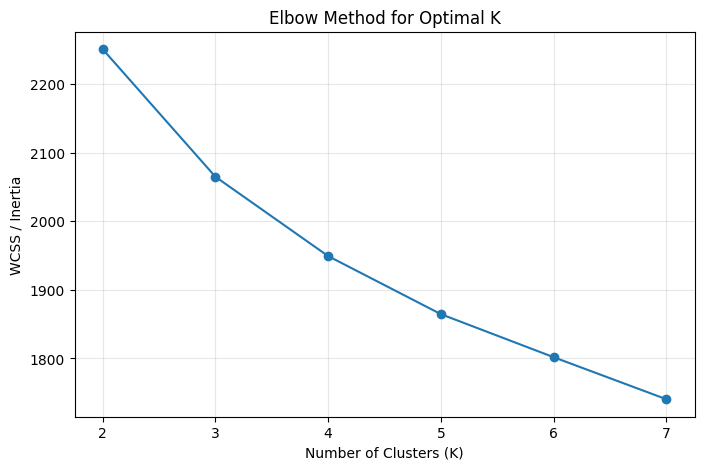

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

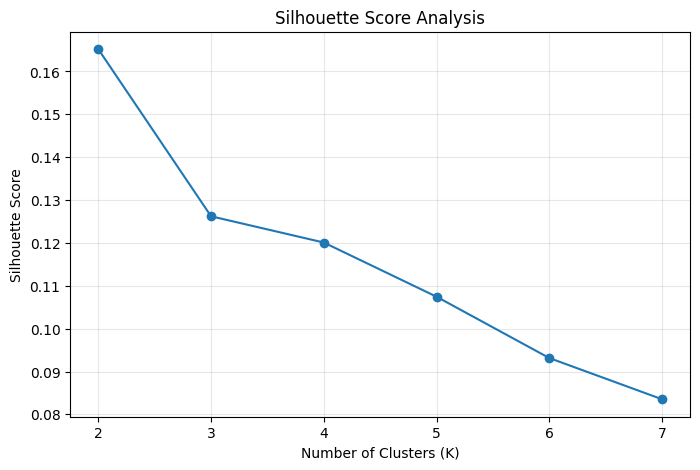

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

In [39]:
# Train final K-Means model
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Generate cluster labels
cluster_labels = final_kmeans.fit_predict(X_cluster)

# Add cluster labels to original features
clustered_df = X.copy()
clustered_df["Cluster"] = cluster_labels
clustered_df["Heart_Disease"] = y.values

print("K-Means clustering completed!")
print("\nCluster Distribution:")
print(clustered_df["Cluster"].value_counts().sort_index())

display(clustered_df.head())

K-Means clustering completed!

Cluster Distribution:
Cluster
0    137
1    166
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Cluster,Heart_Disease
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,1,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,1,0


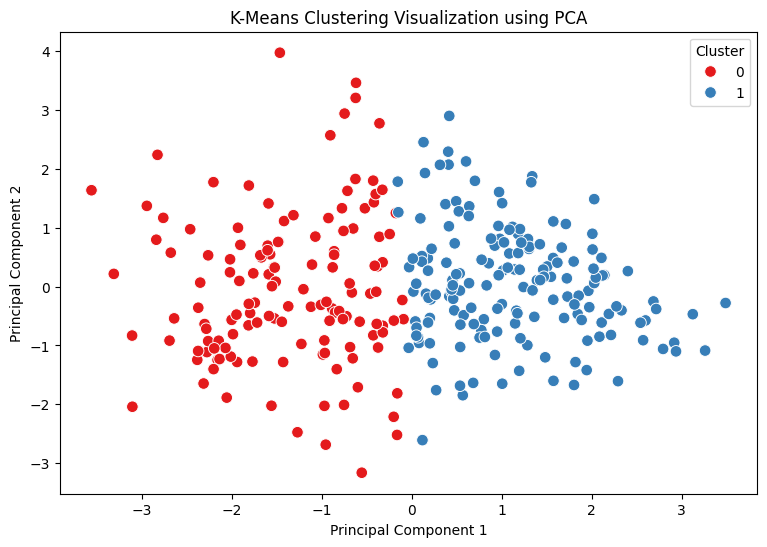

Total variance explained: 38.37 %


In [40]:
from sklearn.decomposition import PCA
import numpy as np
from scipy import sparse

# Convert sparse matrix to dense if required
X_dense = (
    X_cluster.toarray()
    if sparse.issparse(X_cluster)
    else X_cluster
)

# Reduce dimensions to 2
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_dense)

# Create visualization dataframe
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels
})

# Plot clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=70
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.show()

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA plot shows:
- Red points represent Cluster 0.
- Blue points represent Cluster 1.
- The clusters are relatively distinguishable along Principal Component 1.
- Some overlap exists between the two groups.

In [41]:
# Compare cluster assignments with actual labels
cluster_comparison = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["Heart_Disease"]
)

cluster_comparison.columns = [
    "No Heart Disease",
    "Heart Disease"
]

display(cluster_comparison)

,No Heart Disease,Heart Disease
Cluster,,
0,35,102
1,129,37


In [42]:
cluster_percentage = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["Heart_Disease"],
    normalize="index"
) * 100

cluster_percentage.columns = [
    "No Heart Disease",
    "Heart Disease"
]

display(cluster_percentage.round(2))

,No Heart Disease,Heart Disease
Cluster,,
0,25.55,74.45
1,77.71,22.29


In [43]:
cluster_profile = clustered_df.groupby("Cluster").agg({
    "age": "mean",
    "trestbps": "mean",
    "chol": "mean",
    "thalach": "mean",
    "oldpeak": "mean",
    "Heart_Disease": "mean"
}).round(2)

cluster_profile.rename(
    columns={
        "age": "Average Age",
        "trestbps": "Average BP",
        "chol": "Average Cholesterol",
        "thalach": "Average Max Heart Rate",
        "oldpeak": "Average Oldpeak",
        "Heart_Disease": "Heart Disease Proportion"
    },
    inplace=True
)

display(cluster_profile)

C:\Users\Vishesh\AppData\Local\Temp\ipykernel_34252\3083388570.py:10: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cluster_profile.rename(


,Average Age,Average BP,Average Cholesterol,Average Max Heart Rate,Average Oldpeak,Heart Disease Proportion
Cluster,,,,,,
0,60.02,136.86,257.01,133.62,1.75,0.74
1,49.83,127.42,238.17,162.80,0.45,0.22


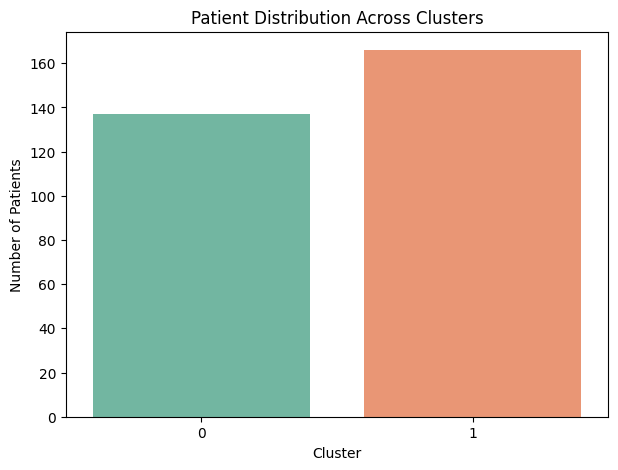

In [44]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=clustered_df,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    legend=False
)

plt.title("Patient Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Patients")

plt.show()

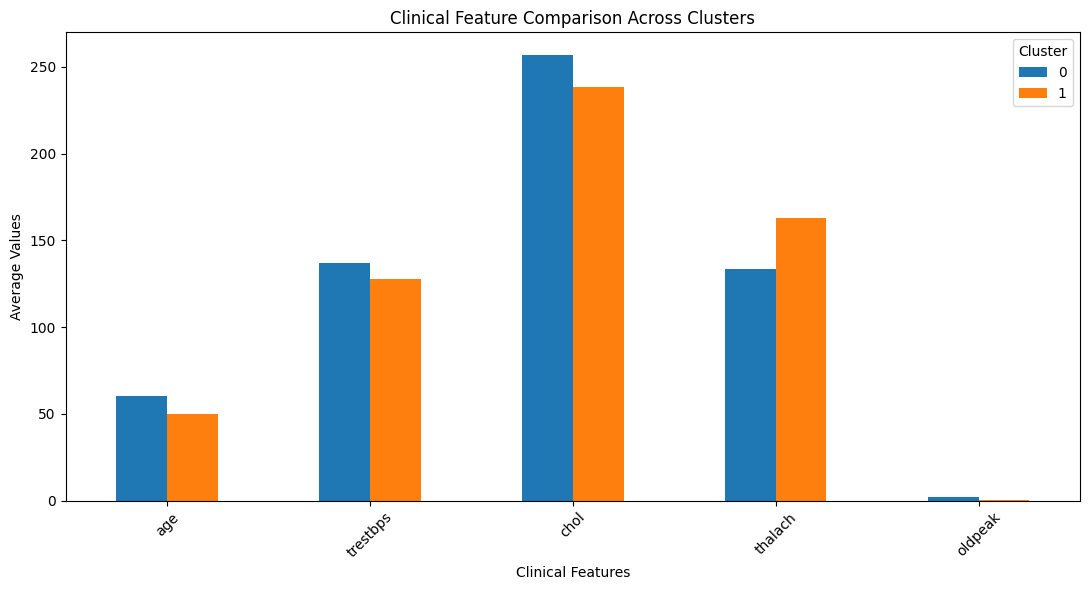

In [45]:
profile_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

cluster_profile_plot = (
    clustered_df.groupby("Cluster")[profile_features]
    .mean()
)

cluster_profile_plot.T.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Clinical Feature Comparison Across Clusters")
plt.xlabel("Clinical Features")
plt.ylabel("Average Values")
plt.xticks(rotation=45)

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()